[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/philippe-amuzuga/Meca-IA_Ed2026/blob/main/meca-ia/C17/E17-2_Contact_Hertz_CORRIGE.ipynb)

# Contact bille et plan : retrouver la loi de Hertz

## Le contexte

Une bille d'acier appuie sur un plan : la pression au centre du contact fixe la tenue du roulement ou de la butée, et un calcul élastique la donne pour chaque charge, chaque rayon et chaque matériau de plan. Le bureau d'études a rassemblé 400 calculs et voudrait un substitut : un modèle qui donne la pression sans refaire le calcul, et dont on sache dire jusqu'où il reste fiable.

La grandeur à prédire est une pression en MPa : c'est un problème de régression.

Défi : prédire `pression_max_MPa` et obtenir un R² supérieur à celui du modèle de départ sur la base de test. Ce modèle de départ est une régression linéaire sur les entrées telles que le calcul les a reçues ; il atteint un R² de 0,817. À vous de trouver une forme qui épouse la loi. La règle de découpage est fixée plus bas. La base de test sert à mesurer, jamais à apprendre ni à régler.

## Les données

Fichier `MecaIA-Contact_Hertz.xlsx`, dans le dossier `donnees` du dépôt : 400 calculs, 6 colonnes. Une ligne est un calcul élastique du contact entre une bille en acier et un plan.

| Colonne | Signification | Unité |
|---|---|---|
| `charge_N` | charge normale appliquée à la bille | N |
| `rayon_bille_mm` | rayon de la bille | mm |
| `module_plan_GPa` | module d'Young du plan | GPa |
| `poisson_plan` | coefficient de Poisson du plan (quelques cases vides) | sans unité |
| `maillage` | finesse du maillage du calcul : `grossier`, `moyen` ou `fin` | catégorie |
| `pression_max_MPa` | cible : pression maximale au centre du contact | MPa |

Origine : jeu simulé, d'après la théorie du contact de Hertz (sphère sur plan), avec un biais du maillage sur le pic de pression et une dispersion du calcul. Il enseigne une méthode, et aucune conclusion de dimensionnement n'en découle.

### Étape 1 : charger le fichier et regarder sa forme

On lit le classeur, puis on vérifie ses dimensions, ses cases vides et l'étendue des entrées et de la cible : la forme d'un fichier se lit sur le fichier entier. Le dossier des données est cherché depuis le dossier du notebook, puis depuis un clone du dépôt ; ouvert seul, par exemple dans Colab, le notebook télécharge une fois le jeu depuis le dépôt public.

In [1]:
from pathlib import Path
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import set_config

set_config(display="text")
GRAINE = 42
FICHIER = "MecaIA-Contact_Hertz.xlsx"
URL_JEU = "https://raw.githubusercontent.com/philippe-amuzuga/Meca-IA_Ed2026/main/donnees/MecaIA-Contact_Hertz.xlsx"

# Le dossier `donnees` du dépôt, cherché depuis le dossier du notebook, puis depuis un clone.
candidats = [Path("..", "..", "donnees"), Path("Meca-IA_Ed2026", "donnees")]
dossier = next((d for d in candidats if (d / FICHIER).is_file()), None)
if dossier is None:
    # Notebook ouvert seul (Colab) : copie unique du jeu depuis le dépôt public.
    dossier = Path("donnees")
    dossier.mkdir(exist_ok=True)
    try:
        urllib.request.urlretrieve(URL_JEU, dossier / FICHIER)
    except OSError as erreur:
        raise FileNotFoundError(
            "Jeu introuvable : clonez le dépôt, ou vérifiez la connexion pour le télécharger.") from erreur
df = pd.read_excel(dossier / FICHIER)

cible = "pression_max_MPa"
print("dimensions :", df.shape)
vides = df.isna().sum()
print("cases vides :", vides[vides > 0].to_dict())
etendue = df.describe().loc[["min", "max"]].T
etendue["rapport"] = etendue["max"] / etendue["min"]
print(etendue.round(2).to_string())
df.head(3)

dimensions : (400, 6)
cases vides : {'poisson_plan': 10}
                     min      max  rapport
charge_N           10.40   998.50    96.01
rayon_bille_mm      5.00    24.85     4.97
module_plan_GPa    70.70   209.60     2.96
poisson_plan        0.26     0.34     1.31
pression_max_MPa  298.60  4095.20    13.71


,charge_N,rayon_bille_mm,module_plan_GPa,poisson_plan,maillage,pression_max_MPa
0,10.4,7.98,185.4,0.280,moyen,697.8
1,59.1,8.37,191.8,0.301,fin,1272.1
2,14.6,6.12,153.2,0.275,grossier,835.0


Lecture du résultat : 400 calculs, 6 colonnes ; seul le coefficient de Poisson a des cases vides (10). La charge s'étend sur un rapport de 96 entre sa plus petite et sa plus grande valeur, le rayon sur 5, le module sur 3,0. Une variable qui s'étend sur plus d'une puissance de dix est souvent une variable dont l'effet est un produit de puissances.

### Préparation du dépôt (Colab)

Ouvert seul dans Colab, ce notebook ne voit pas le dossier `donnees/` du dépôt. La cellule suivante ne télécharge rien : elle cherche ce dossier (à deux dossiers au-dessus du notebook, à côté de lui ou dans un clone nommé `Meca-IA_Ed2026`), vérifie la présence du classeur du défi et, sur Colab, liste ce qui manque. Pour le fournir, ouvrez le panneau des fichiers de Colab, créez le dossier `donnees` à la racine de l'espace de travail et téléversez-y le classeur listé, pris dans le dépôt.

In [ ]:
# Préparation du dépôt (utile sur Colab) : cette cellule ne télécharge rien.
import os
from pathlib import Path

JEUX_LUS = ["MecaIA-Contact_Hertz.xlsx"]                  # le classeur lu par ce notebook


def chercher(dossier):
    """Le dossier du dépôt cherché depuis le notebook, puis depuis un clone ; None s'il est introuvable."""
    for base in (Path("..", ".."), Path("."), Path("Meca-IA_Ed2026")):
        if (base / dossier).is_dir():
            return base / dossier
    return None


donnees = chercher("donnees")
manque = [f"donnees/{nom}" for nom in JEUX_LUS if donnees is None or not (donnees / nom).is_file()]
if manque and "COLAB_RELEASE_TAG" in os.environ:          # variable posée par Colab
    print("À téléverser dans l'espace de travail de Colab, panneau des fichiers :")
    print("\n".join("  " + nom for nom in manque))


### Étape 2 : mettre le test de côté

Un quart des calculs est mis de côté avant tout apprentissage, tout réglage et toute comparaison avec la cible. La graine 42 fixe le tirage : chacun obtient la même base de test, et les scores se comparent.

In [2]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=cible)
y = df[cible]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=GRAINE)
print("apprentissage :", len(X_train), "calculs")
print("test :", len(X_test), "calculs")

apprentissage : 300 calculs
test : 100 calculs


### Étape 3 : regarder la pression contre la charge, sur l'apprentissage

La figure place les calculs d'apprentissage en échelles linéaires, puis en échelles logarithmiques. Un nuage qui devient une droite en échelles logarithmiques trahit une loi de puissance.

pente de ln(pression) contre ln(charge) : 0.35


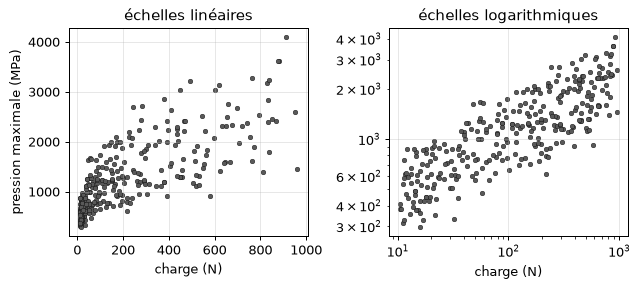

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.3))
for ax, echelle in zip(axes, ["linear", "log"]):
    ax.scatter(X_train["charge_N"], y_train, s=14, color="0.35", edgecolor="black", linewidth=0.3)
    ax.set(xlabel="charge (N)", xscale=echelle, yscale=echelle, title="échelles " + ("linéaires" if echelle == "linear" else "logarithmiques"))
    ax.grid(alpha=0.3)
axes[0].set_ylabel("pression maximale (MPa)")
plt.tight_layout()
plt.show()
pente_charge = np.polyfit(np.log(X_train["charge_N"]), np.log(y_train), 1)[0]
print("pente de ln(pression) contre ln(charge) :", round(pente_charge, 3))

Lecture du résultat : en échelles linéaires, la pression monte vite puis s'aplatit, et le nuage s'élargit ; en échelles logarithmiques, il se resserre autour d'une droite, dont la pente est de 0,35 : doubler la charge multiplie la pression par 1,27, loin d'un facteur 2. Une régression linéaire sur les valeurs brutes ne peut pas représenter une telle loi. Cette pente est lue sur l'apprentissage seul, pour toutes les autres entrées confondues.

### Étape 4 : construire le modèle de départ

Le modèle de départ est une régression linéaire sur les entrées brutes. Le maillage devient des colonnes de 0 et de 1, les coefficients de Poisson non relevés sont remplacés par la médiane de l'apprentissage, et chaque variable numérique est ramenée à une moyenne nulle et à un écart type de 1. La préparation s'apprend sur `X_train` seul et s'applique ensuite au test.

In [4]:
# Solution :
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

mesures = ["charge_N", "rayon_bille_mm", "module_plan_GPa", "poisson_plan"]
preprocessor = make_column_transformer(
    (OneHotEncoder(), ["maillage"]),
    (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), mesures))
modele = make_pipeline(preprocessor, LinearRegression())
modele.fit(X_train, y_train)
# Fin de la solution

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('onehotencoder',
                                                  OneHotEncoder(),
                                                  ['maillage']),
                                                 ('pipeline',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['charge_N', 'rayon_bille_mm',
                                                   'module_plan_GPa',
                                                   'poisson_plan'])])),
                ('linearregression', LinearRegression())])

### Étape 5 : mesurer sur la base de test

Le modèle prédit des calculs qu'il n'a jamais vus. Trois indicateurs sont lus : le coefficient de détermination R², et deux erreurs en MPa, la racine de l'erreur quadratique moyenne (RMSE) et l'erreur absolue moyenne (MAE). Deux témoins sans loi physique situent le résultat : un modèle qui répond toujours la moyenne de l'apprentissage, et une droite sur la seule charge.

In [5]:
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

y_pred = modele.predict(X_test)
score_depart = r2_score(y_test, y_pred)
score_temoin = r2_score(y_test, np.full(len(y_test), y_train.mean()))
charge_seule = LinearRegression().fit(X_train[["charge_N"]], y_train)
score_charge = r2_score(y_test, charge_seule.predict(X_test[["charge_N"]]))
print(f"R² : {score_depart:.3f}")
print(f"RMSE : {root_mean_squared_error(y_test, y_pred):.1f} MPa")
print(f"MAE : {mean_absolute_error(y_test, y_pred):.1f} MPa")
print(f"R² du témoin (toujours la moyenne de l'apprentissage) : {score_temoin:.3f}")
print(f"R² d'une droite sur la charge seule : {score_charge:.3f}")
print(f"prédictions négatives : {(y_pred < 0).sum()} sur {len(y_pred)}")

R² : 0.817
RMSE : 283.9 MPa
MAE : 226.8 MPa
R² du témoin (toujours la moyenne de l'apprentissage) : -0.042
R² d'une droite sur la charge seule : 0.540
prédictions négatives : 1 sur 100


Lecture du résultat : le R² est de 0,817 et l'erreur absolue moyenne de 227 MPa, pour une pression moyenne de 1151 MPa sur la base de test. Le témoin qui répond toujours la moyenne n'explique rien (-0,042) ; une droite sur la seule charge explique 0,540. Les autres variables comptent donc beaucoup, mais la droite les additionne, alors que la loi les multiplie. C'est ce chiffre, mesuré sur des calculs que le modèle n'a jamais vus, que l'on a le droit d'annoncer.

## Pour aller plus loin : une loi de puissance, et jusqu'où elle vaut

Le modèle de départ de l'étape 4 reste le score de référence du défi. Les cellules suivantes montrent comment le dépasser sans regarder le test pour choisir. La première compare, par validation croisée sur l'apprentissage seul, la droite, un polynôme de degré 2, une forêt aléatoire, un gradient boosting et une droite sur les logarithmes : la pression est remplacée par son logarithme, ainsi que la charge, le rayon et le module, de sorte que le produit de puissances d'une loi de Hertz devient une somme. La deuxième lit les exposants que la droite sur les logarithmes a trouvés. La troisième est un test de domaine : on apprend sur les trois quarts de l'apprentissage aux charges les plus faibles et on juge sur les charges plus fortes. La quatrième mesure le modèle retenu une seule fois sur le test.

In [6]:
# Solution :
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_score
from sklearn.preprocessing import FunctionTransformer, PolynomialFeatures

logs = ["charge_N", "rayon_bille_mm", "module_plan_GPa"]
prep_log = make_column_transformer(
    (FunctionTransformer(np.log), logs),
    (OneHotEncoder(), ["maillage"]),
    (SimpleImputer(strategy="median"), ["poisson_plan"]))
candidats = {
    "droite (modèle de départ)": modele,
    "polynôme de degré 2": make_pipeline(preprocessor, PolynomialFeatures(2), StandardScaler(), LinearRegression()),
    "forêt aléatoire": make_pipeline(preprocessor, RandomForestRegressor(300, random_state=GRAINE)),
    "gradient boosting par histogrammes": make_pipeline(preprocessor, HistGradientBoostingRegressor(random_state=GRAINE)),
    "droite sur les logarithmes": TransformedTargetRegressor(
        make_pipeline(prep_log, LinearRegression()), func=np.log, inverse_func=np.exp)}
plis = KFold(n_splits=5, shuffle=True, random_state=GRAINE)
notes_cv = {}
for nom, candidat in candidats.items():
    notes = cross_val_score(candidat, X_train, y_train, cv=plis, scoring="r2")
    notes_cv[nom] = notes.mean()
    print(f"{nom} : R² {notes.mean():.3f} +/- {notes.std():.3f} sur 5 plis")
nom_retenu = max(notes_cv, key=notes_cv.get)
print("modèle retenu par la validation croisée :", nom_retenu)
# Fin de la solution

droite (modèle de départ) : R² 0.852 +/- 0.038 sur 5 plis
polynôme de degré 2 : R² 0.960 +/- 0.016 sur 5 plis
forêt aléatoire : R² 0.947 +/- 0.014 sur 5 plis
gradient boosting par histogrammes : R² 0.967 +/- 0.009 sur 5 plis
droite sur les logarithmes : R² 0.999 +/- 0.000 sur 5 plis
modèle retenu par la validation croisée : droite sur les logarithmes


In [7]:
# Solution :
loi = clone(candidats["droite sur les logarithmes"]).fit(X_train, y_train)
exposants = dict(zip(logs, loi.regressor_[-1].coef_[:3]))
for nom, e in exposants.items():
    print(f"exposant de {nom} : {e:+.3f}")
# Fin de la solution

exposant de charge_N : +0.332
exposant de rayon_bille_mm : -0.668
exposant de module_plan_GPa : +0.413


In [8]:
# Solution :
limite = X_train["charge_N"].quantile(0.75)
dedans = X_train["charge_N"] <= limite
hors_domaine = {}
for nom, candidat in candidats.items():
    essai = clone(candidat).fit(X_train[dedans], y_train[dedans])
    hors_domaine[nom] = r2_score(y_train[~dedans], essai.predict(X_train[~dedans]))
    print(f"{nom} : R² au-delà de {limite:.0f} N = {hors_domaine[nom]:.3f}")
# Fin de la solution

droite (modèle de départ) : R² au-delà de 369 N = -0.509
polynôme de degré 2 : R² au-delà de 369 N = -5.185
forêt aléatoire : R² au-delà de 369 N = 0.334
gradient boosting par histogrammes : R² au-delà de 369 N = 0.261
droite sur les logarithmes : R² au-delà de 369 N = 0.998


In [9]:
# Solution :
retenu = clone(candidats[nom_retenu]).fit(X_train, y_train)
r2_retenu = r2_score(y_test, retenu.predict(X_test))
print(f"{nom_retenu}, mesuré une fois sur le test : R² {r2_retenu:.3f}")
print(f"gain sur le modèle de départ : {r2_retenu - score_depart:+.3f}")
# Fin de la solution

droite sur les logarithmes, mesuré une fois sur le test : R² 0.999
gain sur le modèle de départ : +0.183


Lecture du résultat : en validation croisée, la droite sur les logarithmes atteint 0,999, contre 0,852 pour la droite sur les valeurs brutes, 0,960 pour le polynôme, 0,947 pour la forêt et 0,967 pour le gradient boosting : le modèle retenu est « droite sur les logarithmes ». Les exposants qu'elle a trouvés sont ceux d'une loi de Hertz : 0,33 pour la charge, -0,67 pour le rayon (un tiers et moins deux tiers), et 0,41 pour le module du plan (moins de deux tiers, car le module de contact combine ceux de la bille et du plan). Mesuré une seule fois sur le test, ce modèle donne un R² de 0,999, soit 0,183 de plus que le modèle de départ. Le test de domaine montre la limite des autres modèles : au-delà de 369 N, charge que ces modèles n'ont jamais vue, la forêt n'atteint qu'un R² de 0,33, le gradient boosting 0,26 et la droite sur valeurs brutes -0,51, alors que la droite sur les logarithmes garde 0,998. Un modèle dont la forme est celle de la loi extrapole ; un modèle qui découpe les données ne sait que répéter ce qu'il a vu.

## Le score de référence

Le score publié est le R² du modèle de départ de l'étape 4 sur la base de test. L'empreinte identifie cette base de test : si la vôtre diffère, le découpage n'est pas le même et les scores ne se comparent pas.

In [10]:
import hashlib

score = r2_score(y_test, modele.predict(X_test))
positions = ",".join(str(i) for i in sorted(X_test.index))
print("EMPREINTE_TEST =", hashlib.sha256(positions.encode("ascii")).hexdigest())
print("SCORE_REFERENCE r2 = %.3f" % score)

EMPREINTE_TEST = 16666d6475284417762f1ddb1c18c1398141467d82c7df196083590c71c883a4
SCORE_REFERENCE r2 = 0.817


## Synthèse

1. Les grandeurs qui s'étendent sur plusieurs puissances de dix invitent à tracer en échelles logarithmiques : une droite en échelles logarithmiques est une loi de puissance, ici de pente 0,35 pour la charge.
2. Une régression linéaire sur les valeurs brutes additionne des effets que la loi multiplie : elle atteint 0,817 sur la base de test. Sur les logarithmes, la même méthode donne 0,999, avec des exposants qui sont ceux de la théorie.
3. À l'intérieur du domaine des calculs, la forêt (0,947) et le gradient boosting (0,967) s'en tirent bien en validation croisée ; hors du domaine, ils tombent à 0,33 et 0,26.
4. Un substitut qui épouse la forme de la loi peut sortir un peu du domaine d'apprentissage ; un substitut sans forme ne le peut pas. Dans les deux cas, la validité se teste sur des charges plus fortes que celles de l'apprentissage, jamais sur le test.